# Wine Quality multiclass classification

попробуем взять датасет Wine Quality, и разделить `quality` на 3 класса и обучить MLP

по классам:
- `0` — плохо (`quality <= 5`)
- `1` — среднее (`quality == 6`)
- `2` — хорошее (`quality >= 7`)

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from ucimlrepo import fetch_ucirepo
from minigrad.nn import Linear, ReLU, Sequential, BatchNormalization, Dropout
from minigrad.losses import CrossEntropyLoss
from minigrad.optim import Adam
from minigrad.data import DataLoader
from minigrad.trainer import Trainer
np.random.seed(42)


## датасет
id=186 — Wine Quality из UCI Machine Learning Repository.

In [2]:
wine = fetch_ucirepo(id=186)

X_df = wine.data.features.copy()
y_df = wine.data.targets.copy()

print("X shape:", X_df.shape)
print("y shape:", y_df.shape)


X shape: (6497, 11)
y shape: (6497, 1)


посмотрим что там есть

In [3]:
X_df.head(10)


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4
5,7.4,0.66,0.00,1.8,0.075,13.0,40.0,0.9978,3.51,0.56,9.4
6,7.9,0.60,0.06,1.6,0.069,15.0,59.0,0.9964,3.30,0.46,9.4
7,7.3,0.65,0.00,1.2,0.065,15.0,21.0,0.9946,3.39,0.47,10.0
8,7.8,0.58,0.02,2.0,0.073,9.0,18.0,0.9968,3.36,0.57,9.5
9,7.5,0.50,0.36,6.1,0.071,17.0,102.0,0.9978,3.35,0.80,10.5


посмотрим на таргет

In [4]:
y_df.head(10)


,quality
0,5
1,5
2,5
3,6
4,5
5,5
6,5
7,7
8,7
9,5


статистика


In [5]:
X_df.describe().T


,count,mean,std,min,25%,50%,75%,max
fixed_acidity,6497.0,7.215307,1.296434,3.80000,6.40000,7.00000,7.70000,15.90000
volatile_acidity,6497.0,0.339666,0.164636,0.08000,0.23000,0.29000,0.40000,1.58000
citric_acid,6497.0,0.318633,0.145318,0.00000,0.25000,0.31000,0.39000,1.66000
residual_sugar,6497.0,5.443235,4.757804,0.60000,1.80000,3.00000,8.10000,65.80000
chlorides,6497.0,0.056034,0.035034,0.00900,0.03800,0.04700,0.06500,0.61100
free_sulfur_dioxide,6497.0,30.525319,17.749400,1.00000,17.00000,29.00000,41.00000,289.00000
total_sulfur_dioxide,6497.0,115.744574,56.521855,6.00000,77.00000,118.00000,156.00000,440.00000
density,6497.0,0.994697,0.002999,0.98711,0.99234,0.99489,0.99699,1.03898
pH,6497.0,3.218501,0.160787,2.72000,3.11000,3.21000,3.32000,4.01000
sulphates,6497.0,0.531268,0.148806,0.22000,0.43000,0.51000,0.60000,2.00000


теперь разделим quality на 3 класса и глянем на статистику

In [6]:
quality = y_df.to_numpy().ravel()
y = np.zeros_like(quality, dtype=np.int64)
y[quality == 6] = 1
y[quality >= 7] = 2
class_names = np.array(["bad", "medium", "good"])
classes, counts = np.unique(y, return_counts=True)
class_table = pd.DataFrame({
    "class_id": classes,
    "class_name": class_names[classes],
    "count": counts,
    "share": counts / counts.sum(),
})

class_table


,class_id,class_name,count,share
0,0,bad,2384,0.366939
1,1,medium,2836,0.436509
2,2,good,1277,0.196552


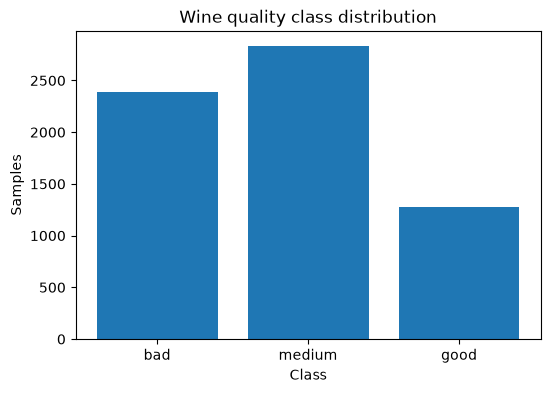

In [7]:
plt.figure(figsize=(6, 4))
plt.bar(class_table["class_name"], class_table["count"])
plt.xlabel("Class")
plt.ylabel("Samples")
plt.title("Wine quality class distribution")
plt.show()


дальше нужно разделить выборку на train и test в отношении 0,8/0,2

In [9]:
X = X_df.to_numpy(dtype=np.float64)

indices = np.arange(len(X))
np.random.shuffle(indices)

split = int(0.8 * len(X))
train_idx = indices[:split]
test_idx = indices[split:]

X_train, X_test = X[train_idx], X[test_idx]
y_train, y_test = y[train_idx], y[test_idx]

print("train:", X_train.shape, y_train.shape)
print("test :", X_test.shape, y_test.shape)


train: (5197, 11) (5197,)
test : (1300, 11) (1300,)


отмасштабируем по train, чтобы не поймать data leakage

$$
x' = \frac{x - \mu}{\sigma}
$$



In [10]:
mean = X_train.mean(axis=0)
std = X_train.std(axis=0)
std[std == 0] = 1.0

X_train = (X_train - mean) / std
X_test = (X_test - mean) / std

pd.DataFrame({
    "feature": X_df.columns,
    "train_mean_after_norm": X_train.mean(axis=0),
    "train_std_after_norm": X_train.std(axis=0),
}).round(3)


,feature,train_mean_after_norm,train_std_after_norm
0,fixed_acidity,-0.0,1.0
1,volatile_acidity,-0.0,1.0
2,citric_acid,0.0,1.0
3,residual_sugar,-0.0,1.0
4,chlorides,-0.0,1.0
5,free_sulfur_dioxide,-0.0,1.0
6,total_sulfur_dioxide,0.0,1.0
7,density,0.0,1.0
8,pH,0.0,1.0
9,sulphates,-0.0,1.0


соберем модель, тут mlp, по размерностям переходы 11 - 64 - 32 - 3

между слоями BatchNorm, ReLU, Dropout, оптимизатор Adam, loss - CrossEntropyLoss

In [35]:
train_loader = DataLoader(
    X_train,
    y_train,
    batch_size=64,
    shuffle=True,
)

model = Sequential(
    Linear(X_train.shape[1], 128),
    BatchNormalization(128),
    ReLU(),
    Dropout(0.1),
    Linear(128, 64),
    ReLU(),
    Linear(64, 3),
)

loss_fn = CrossEntropyLoss()
optimizer = Adam(model, lr=0.0005)
trainer = Trainer(model, loss_fn, optimizer)

model


Sequential(
    Linear(in_features=11, out_features=128, bias=True)
    BatchNormalization(num_features=128, eps=1e-05, momentum=0.1, affine=True)
    ReLU()
    Dropout(p=0.1)
    Linear(in_features=128, out_features=64, bias=True)
    ReLU()
    Linear(in_features=64, out_features=3, bias=True)
)

обучаем

In [36]:
history = trainer.fit(train_loader, epochs=300)

print("loss:", history["loss"][0], "->", history["loss"][-1])


loss: 0.9522551670920855 -> 0.5502373765122259


График loss

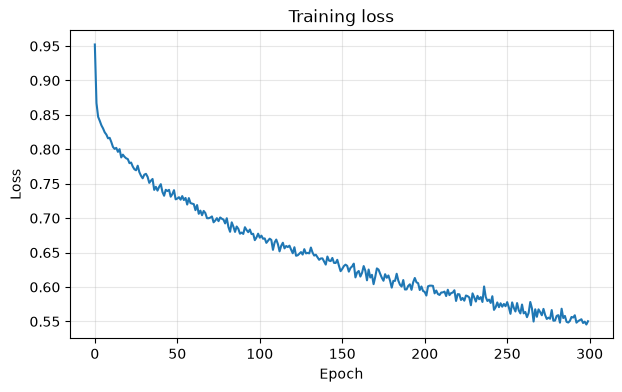

In [37]:
plt.figure(figsize=(7, 4))
plt.plot(history["loss"])
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training loss")
plt.grid(True, alpha=0.3)
plt.show()


Проверяем на test

In [38]:
model.eval()

logits = model(X_test)
pred = np.argmax(logits, axis=1)

accuracy = np.mean(pred == y_test)

print("test accuracy:", accuracy)


test accuracy: 0.6823076923076923


глянем что вышло

In [39]:
pred_table = pd.DataFrame({
    "true_id": y_test[:25],
    "true": class_names[y_test[:25]],
    "pred_id": pred[:25],
    "pred": class_names[pred[:25]],
})

pred_table


,true_id,true,pred_id,pred
0,2,good,2,good
1,2,good,2,good
2,0,bad,0,bad
3,1,medium,1,medium
4,0,bad,0,bad
5,0,bad,0,bad
6,0,bad,1,medium
7,1,medium,1,medium
8,2,good,2,good
9,1,medium,1,medium


### Confusion matrix

In [40]:
cm = np.zeros((3, 3), dtype=int)

for true_class, pred_class in zip(y_test, pred):
    cm[true_class, pred_class] += 1

cm_df = pd.DataFrame(
    cm,
    index=[f"true_{name}" for name in class_names],
    columns=[f"pred_{name}" for name in class_names],
)

cm_df


,pred_bad,pred_medium,pred_good
true_bad,354,117,13
true_medium,116,373,78
true_good,17,72,160


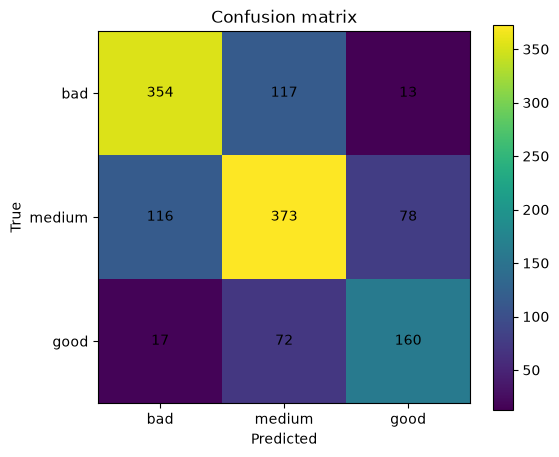

In [41]:
plt.figure(figsize=(6, 5))
plt.imshow(cm)
plt.xticks(range(3), class_names)
plt.yticks(range(3), class_names)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion matrix")

for i in range(3):
    for j in range(3):
        plt.text(j, i, cm[i, j], ha="center", va="center")

plt.colorbar()
plt.show()


Итог
Модель получила test accuracy ≈ 68%. это лучше радномной модели, для улучшения метрки можно поиграться с гиперпараметрами и усложнить модель доп слоями
Основные ошибки — между соседними классами (`bad ↔ medium`, `medium ↔ good`), так как они близки по признакам.